In [23]:

# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df = pd.read_csv("../dataset/cleaned/retail_sales_cleaned.csv")

# Convert transaction date to datetime
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (12575, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [24]:

# Numerical summary
print("Numerical Summary:")
display(df.describe().T)

# Categorical summary
print("\nCategorical Summary:")
display(df.describe(include="object").T)

# Missing-value check
print("\nMissing Values:")
display(df.isnull().sum())


Numerical Summary:


,count,mean,min,25%,50%,75%,max,std
Price Per Unit,12575.0,23.348191,5.0,14.0,23.0,32.0,41.0,10.480413
Quantity,12575.0,5.558648,1.0,3.0,6.0,8.0,10.0,2.79016
Total Spent,12575.0,130.11495,5.0,55.0,111.0,192.0,410.0,92.327187
Transaction Date,12575,2023-07-12 20:23:41.105368064,2022-01-01 00:00:00,2022-09-30 00:00:00,2023-07-13 00:00:00,2024-04-24 00:00:00,2025-01-18 00:00:00,NaN



Categorical Summary:


,count,unique,top,freq
Transaction ID,12575,12575,TXN_2407494,1
Customer ID,12575,25,CUST_05,544
Category,12575,8,Electric household essentials,1591
Item,12575,201,Unknown,1213
Payment Method,12575,3,Cash,4310
Location,12575,2,Online,6354
Discount Applied,12575,3,True,4219



Missing Values:


Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64

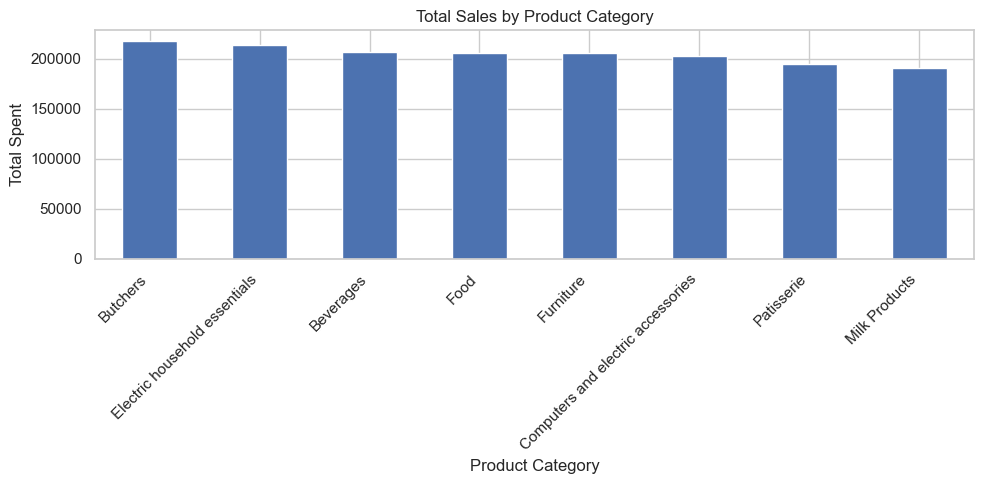

In [25]:

# Total sales by category

category_sales = (
    df.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spent")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


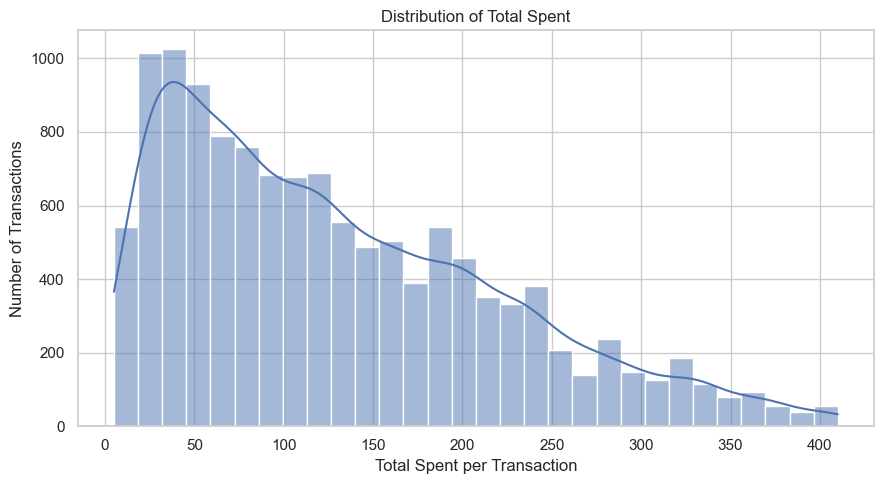

In [26]:

# Step 5: Distribution of Total Spent

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Total Spent",
    bins=30,
    kde=True
)

plt.title("Distribution of Total Spent")
plt.xlabel("Total Spent per Transaction")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()


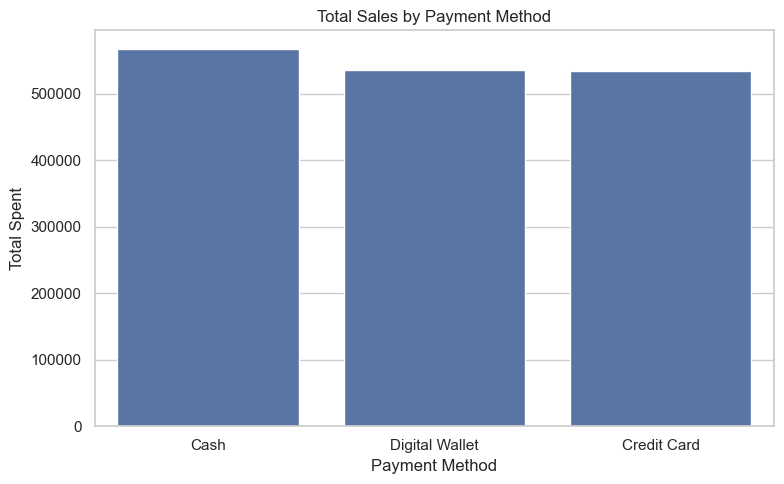

In [27]:

# Step 6: Total sales by payment method

payment_sales = (
    df.groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=payment_sales.index,
    y=payment_sales.values
)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Spent")
plt.tight_layout()
plt.show()


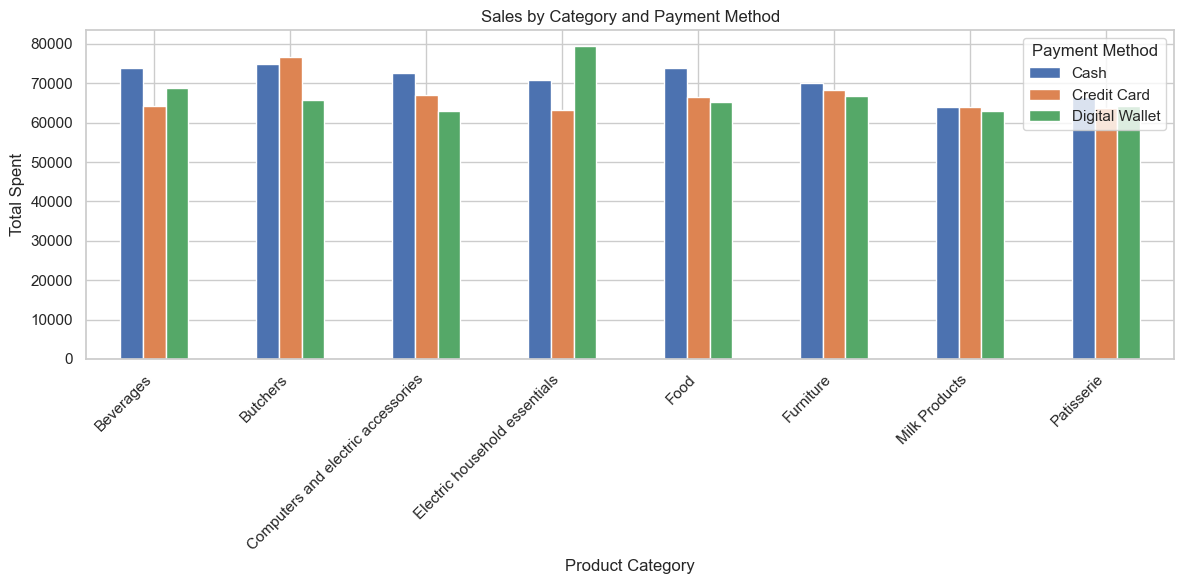

In [28]:

# Step 7: Sales by Category and Payment Method

payment_category = df.pivot_table(
    index="Category",
    columns="Payment Method",
    values="Total Spent",
    aggfunc="sum"
)

payment_category.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Sales by Category and Payment Method")
plt.xlabel("Product Category")
plt.ylabel("Total Spent")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Payment Method")
plt.tight_layout()
plt.show()


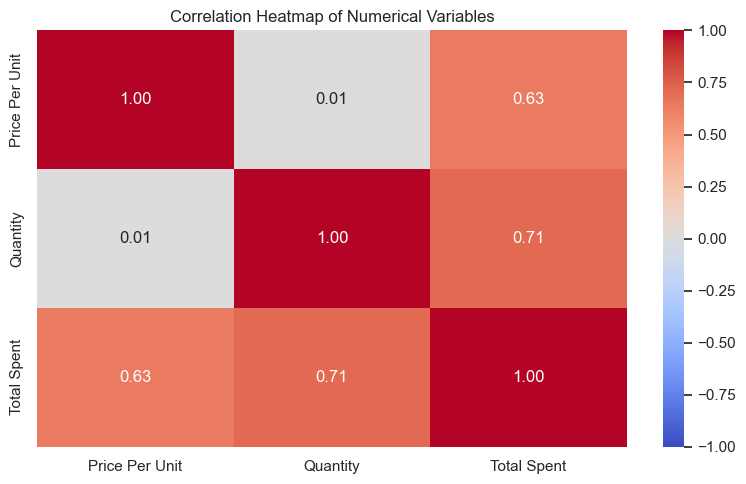

In [29]:

# Step 8: Correlation Heatmap

# Select numerical columns
numeric_df = df[
    ["Price Per Unit", "Quantity", "Total Spent"]
]

# Calculate correlation
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()



plt.show()


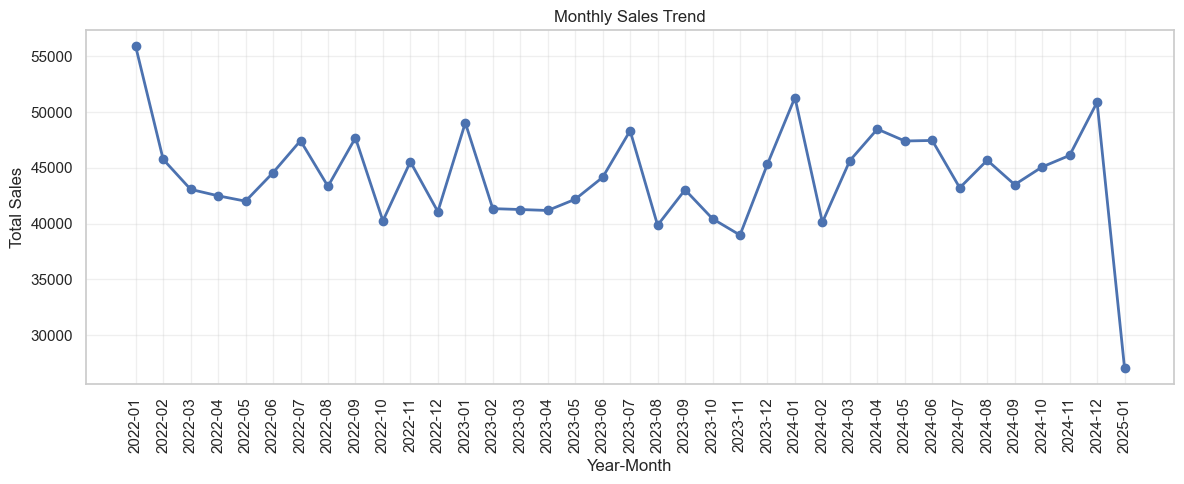

In [30]:

# Step 9: Monthly Sales Trend

# Extract year and month from transaction date
df["Year-Month"] = df["Transaction Date"].dt.to_period("M")

# Calculate total sales for each month
monthly_sales = (
    df.groupby("Year-Month")["Total Spent"]
    .sum()
    .sort_index()
)

# Convert month labels to strings for plotting
monthly_sales.index = monthly_sales.index.astype(str)

# Plot the monthly sales trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()



plt.show()


In [31]:

# Step 10: Generate business insights

# 1. Highest and lowest sales categories
category_sales = df.groupby("Category")["Total Spent"].sum()

print("Highest sales category:", category_sales.idxmax())
print("Highest category sales:", round(category_sales.max(), 2))

print("\nLowest sales category:", category_sales.idxmin())
print("Lowest category sales:", round(category_sales.min(), 2))

# 2. Highest and lowest sales payment methods
payment_sales = df.groupby("Payment Method")["Total Spent"].sum()

print("\nHighest sales payment method:", payment_sales.idxmax())
print("Sales:", round(payment_sales.max(), 2))

print("\nLowest sales payment method:", payment_sales.idxmin())
print("Sales:", round(payment_sales.min(), 2))

# 3. Highest and lowest sales months
monthly_totals = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

print("\nHighest sales month:", monthly_totals.idxmax())
print("Sales:", round(monthly_totals.max(), 2))

print("\nLowest sales month:", monthly_totals.idxmin())
print("Sales:", round(monthly_totals.min(), 2))

# Check transaction counts in the first and last months
monthly_counts = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))
    .size()
)

print("\nTransactions in first month:", monthly_counts.iloc[0])
print("Transactions in last month:", monthly_counts.iloc[-1])


Highest sales category: Butchers
Highest category sales: 217397.0

Lowest sales category: Milk Products
Lowest category sales: 190877.5

Highest sales payment method: Cash
Sales: 566816.0

Lowest sales payment method: Credit Card
Sales: 533368.0

Highest sales month: 2022-01
Sales: 55886.0

Lowest sales month: 2025-01
Sales: 27033.5

Transactions in first month: 390
Transactions in last month: 213


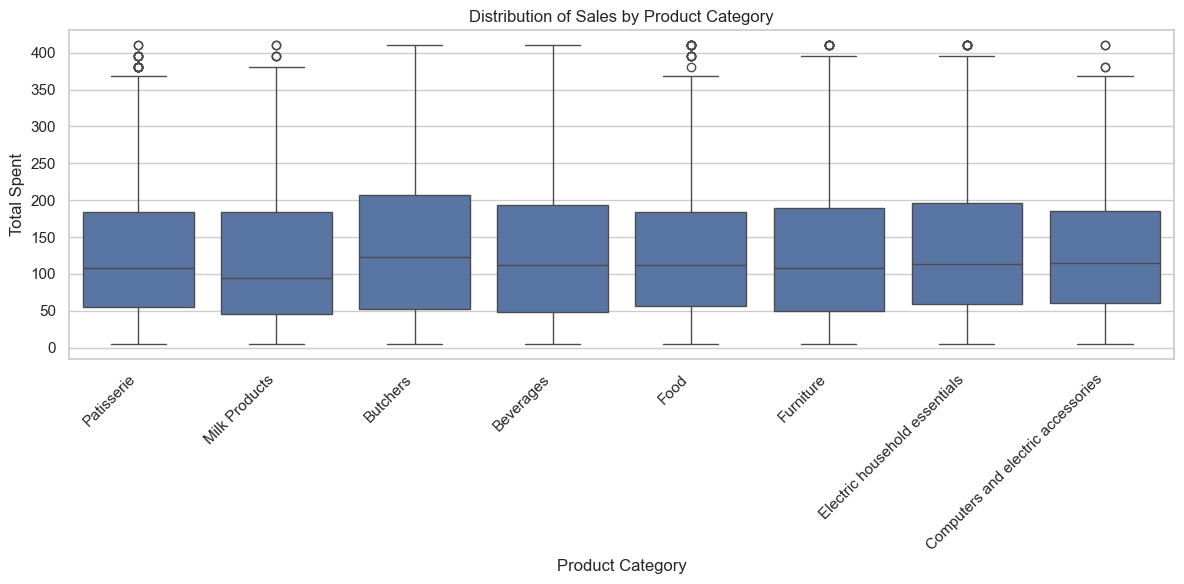

In [32]:

# Boxplot: Total Spent by Category

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Total Spent"
)

plt.title("Distribution of Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Spent")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()



plt.show()


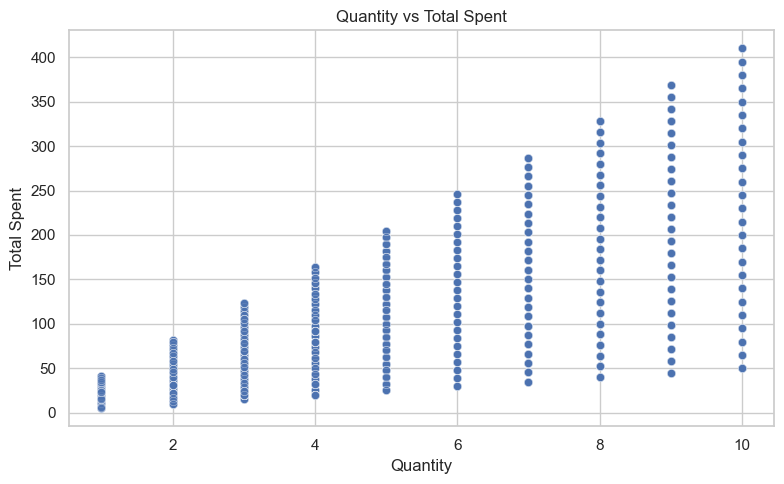

In [33]:

# Step 10: Scatter Plot - Quantity vs Total Spent

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total Spent",
    alpha=0.5
)

plt.title("Quantity vs Total Spent")
plt.xlabel("Quantity")
plt.ylabel("Total Spent")
plt.tight_layout()



plt.show()


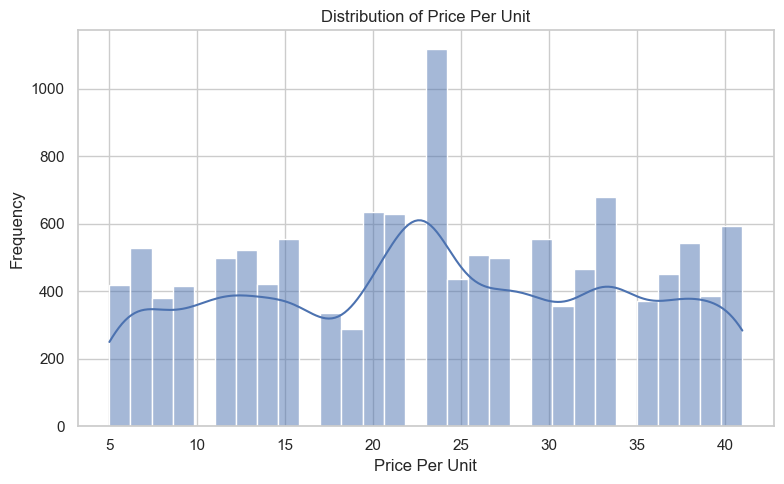

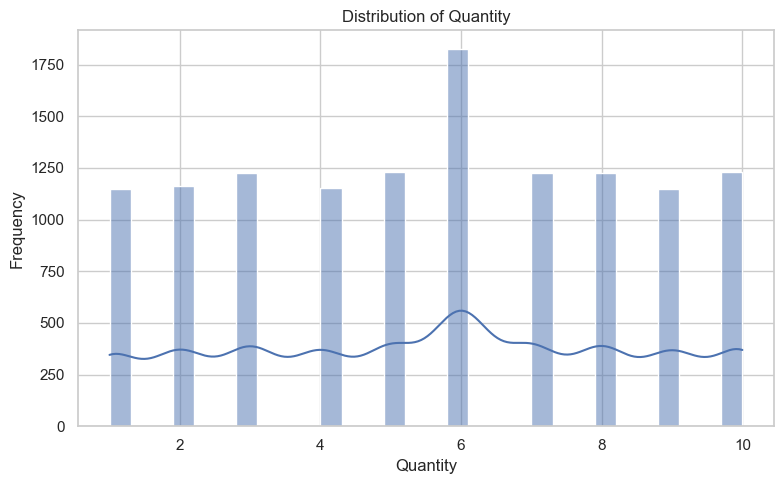

In [34]:

# Step 11: Histograms and KDE plots for other numerical columns

numeric_columns = ["Price Per Unit", "Quantity"]

for column in numeric_columns:
    plt.figure(figsize=(8, 5))
    
    sns.histplot(data=df, x=column, kde=True, bins=30)
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()


# Exploratory Data Analysis (EDA) — Graph Descriptions and Findings

## 1. Sales by Product Category
The bar chart compares total sales across different product categories. Butchers has the highest recorded total sales, while Milk Products has the lowest. The business can investigate product availability, customer demand, and promotions to understand these differences.

## 2. Distribution of Transaction Spending
The histogram with KDE shows the distribution of Total Spent for individual transactions. The distribution is right-skewed, meaning most transactions have lower spending amounts, while a smaller number have higher spending amounts. This information can help the business understand typical customer spending and plan suitable promotions.

## 3. Sales by Payment Method
The bar chart compares total sales across different payment methods. It helps identify which payment methods contribute more to sales. The business can use this information to understand customer payment preferences and make suitable payment options available.

## 4. Sales by Category and Payment Method
The grouped chart compares sales across product categories and payment methods. It helps show whether payment preferences differ between categories. The business can use these comparisons to understand customer buying behaviour and plan convenient payment options.

## 5. Correlation Heatmap
The correlation heatmap shows a positive relationship between Price Per Unit and Total Spent (0.63), and between Quantity and Total Spent (0.71). Price and quantity have almost no linear relationship (0.01). Since Total Spent is calculated from price and quantity, these relationships should be interpreted carefully. Correlation does not prove causation.

## 6. Monthly Sales Trends
The line chart shows how total sales change over time. Monthly sales fluctuate, with several peaks and declines. The business should investigate these changes alongside transaction counts and other available business information before making seasonal or forecasting decisions. The final month may contain incomplete data, so it should be checked before drawing conclusions.

## 7. Box Plot by Product Category
The box plot compares the distribution of transaction spending across product categories. It helps identify differences in typical spending, variation, and potential outliers. Potential outliers should be investigated rather than automatically removed, because they may represent genuine transactions.

## 8. Scatter Plot
The scatter plot shows the relationship between the numerical variables being compared. The pattern of points helps identify possible relationships, clusters, and unusual observations. Any relationship should be interpreted carefully, particularly when one variable is calculated from another.

## 9. Distribution of Price Per Unit
The histogram with KDE shows how frequently different unit prices occur. It helps identify common price ranges, the spread of prices, and unusually high or low values. This can help the business understand its pricing patterns.

## 10. Distribution of Quantity
The histogram with KDE shows the distribution of quantities purchased per transaction. It helps identify common purchase quantities and whether a small number of transactions involve larger quantities. This information can support inventory and purchasing decisions.

## Overall Findings
The analysis shows differences in sales across product categories, variation in transaction spending, and changes in monthly sales. Numerical relationships provide additional information about transaction values, while the distribution plots help explain common prices and purchase quantities.

## Data Limitations
Some original values were missing and were estimated during data cleaning. Therefore, the results are preliminary and may not exactly represent actual sales. Potential outliers were retained because they were not confirmed to be errors. Monthly trends should also be interpreted carefully if the first or last month contains incomplete data.

# Conclusion and Business Recommendations

The Exploratory Data Analysis helped identify sales differences across product categories, customer spending patterns, relationships between numerical variables, and monthly sales fluctuations.

## Key Findings

1. **Category performance:** Butchers recorded the highest total sales, while Milk Products recorded the lowest. The business should investigate product demand, availability, and pricing to understand this difference.

2. **Customer spending:** Transaction spending is right-skewed, meaning most transactions have lower spending amounts and fewer transactions have higher spending amounts. The business can consider suitable promotions to encourage purchases.

3. **Sales trends:** Monthly sales fluctuate over time. The business should compare sales with transaction counts and investigate possible reasons for peaks and declines before making decisions.

## Recommendations

- Review product availability and customer demand across categories.
- Use transaction spending patterns to plan appropriate promotions.
- Monitor monthly sales and transaction counts to identify meaningful changes.
- Improve the reliability of future analysis by collecting complete and accurate transaction data.

## Final Note

These findings are preliminary because some missing values were estimated during data cleaning. Potential outliers were retained because they were not confirmed to be errors. The results should therefore be interpreted with these limitations in mind.